# Counting individual Ovenbirds from call embeddings

This notebook benchmarks clustering-based individual counts **within each recording**. Calls are split by **location**, not at random, so no location occurs in both development and test data.

## Experimental protocol

- **Representations:** original 512-D embedding; PCA with 16 and 64 components; t-SNE with 5 and 16 components.
- **Methods:** thresholded cosine graph + connected components, HDBSCAN, Dirichlet-process Gaussian mixture, average/complete agglomerative clustering, and a pairwise MLP.
- **Selection:** thresholds and other hyperparameters are selected only on the 60% development locations. The selected configuration is then evaluated once on the 40% held-out locations.
- **Metrics:** exact count accuracy, count mean absolute error (MAE), and call-level clustering accuracy after optimal Hungarian label matching.

Important qualifications:

1. `HDBSCAN(min_cluster_size=1)` is undefined. The minimum valid value is 2; noise calls are counted as singleton individuals.
2. t-SNE has no standard out-of-sample transform and is not designed to preserve global distances. Its rows are marked **transductive/exploratory** and should not be treated as directly comparable to the original embedding or development-fitted PCA.
3. The 60% partition is called *development* because it is also used to train the pairwise MLP. The 40% test locations remain untouched during selection and training.

In [1]:
from pathlib import Path
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler

from individual_counting_experiment import (
    RANDOM_STATE,
    agglomerative_labels,
    configuration_score,
    cosine_adjacency_labels,
    dpgmm_labels,
    evaluate_configuration,
    fit_pairwise_mlp,
    hdbscan_labels,
    load_embedding_data,
    location_split,
    pairwise_mlp_labels,
    recording_groups,
    summarize_recording_results,
)

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30)

ROOT = Path.cwd()
DATA_DIR = ROOT / "outputs" / "ovenbird_embeddings"
RESULT_DIR = ROOT / "outputs" / "individual_counting_experiment"
FIGURE_DIR = RESULT_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

## 1. Load and audit the aligned metadata and embeddings

In [2]:
metadata, embeddings = load_embedding_data(
    DATA_DIR / "ovenbird_embedding_metadata.csv",
    DATA_DIR / "ovenbird_embeddings.npy",
)
metadata["partition"] = location_split(metadata)

split_summary = (
    metadata.groupby("partition")
    .agg(
        calls=("embedding_row", "size"),
        locations=("location", "nunique"),
        recordings=("recording_id", "nunique"),
        individuals_within_recordings=("individual_order", "count"),
    )
)
split_summary["call_fraction"] = split_summary["calls"] / len(metadata)

development_groups = recording_groups(metadata, metadata["partition"].eq("development"))
test_groups = recording_groups(metadata, metadata["partition"].eq("test"))
split_summary["eligible_recordings_n_calls_ge_2"] = [
    len(development_groups) if name == "development" else len(test_groups)
    for name in split_summary.index
]

print(f"Embeddings: {embeddings.shape[0]:,} calls × {embeddings.shape[1]} dimensions")
display(split_summary)
display(
    metadata.groupby(["partition", "recording_id"])
    .agg(n_calls=("embedding_row", "size"), true_count=("individual_order", "nunique"))
    .groupby("partition")[["n_calls", "true_count"]]
    .describe()
)

Embeddings: 1,149 calls × 512 dimensions


,calls,locations,recordings,individuals_within_recordings,call_fraction,eligible_recordings_n_calls_ge_2
partition,,,,,,
development,689,166,174,689,0.599652,131
test,460,110,116,460,0.400348,97


n_calls                                               true_count  \
              count      mean       std  min  25%  50%  75%   max      count   
partition                                                                      
development   174.0  3.959770  3.094577  1.0  2.0  3.0  5.0  19.0      174.0   
test          116.0  3.965517  2.617437  1.0  2.0  3.0  6.0  15.0      116.0   

                                                          
                 mean       std  min  25%  50%  75%  max  
partition                                                 
development  1.505747  0.795559  1.0  1.0  1.0  2.0  5.0  
test         1.517241  0.716061  1.0  1.0  1.0  2.0  4.0

Recordings with only one usable call are excluded from benchmarking because every method must return one individual for them. The ground-truth count is computed with `nunique(individual_order)`, not `max(individual_order)`, so the code does not assume labels are contiguous.

## 2. Construct the representations

In [3]:
dev_mask = metadata["partition"].eq("development").to_numpy()

representations = {"embedding_512": embeddings}
representation_regime = {"embedding_512": "inductive"}

for n_components in (16, 64):
    pca = PCA(n_components=n_components, random_state=RANDOM_STATE)
    pca.fit(embeddings[dev_mask])
    representations[f"pca_{n_components}"] = pca.transform(embeddings).astype(np.float32)
    representation_regime[f"pca_{n_components}"] = "inductive"
    print(
        f"PCA {n_components}: {pca.explained_variance_ratio_.sum():.1%} "
        "of development variance retained"
    )

# Exploratory only: t-SNE is fitted jointly because sklearn TSNE has no transform().
for n_components in (5, 16):
    tsne = TSNE(
        n_components=n_components,
        perplexity=30,
        init="pca",
        learning_rate="auto",
        method="exact",
        max_iter=1_000,
        random_state=RANDOM_STATE,
    )
    projected = tsne.fit_transform(embeddings)
    projected = StandardScaler().fit_transform(projected).astype(np.float32)
    representations[f"tsne_{n_components}"] = projected
    representation_regime[f"tsne_{n_components}"] = "transductive_exploratory"

pd.DataFrame(
    {
        "representation": representations.keys(),
        "dimensions": [value.shape[1] for value in representations.values()],
        "evaluation_regime": representation_regime.values(),
    }
)

PCA 16: 75.6% of development variance retained
PCA 64: 94.2% of development variance retained


,representation,dimensions,evaluation_regime
0,embedding_512,512,inductive
1,pca_16,16,inductive
2,pca_64,64,inductive
3,tsne_5,5,transductive_exploratory
4,tsne_16,16,transductive_exploratory


## 3. Define the hyperparameter search

In [4]:
COSINE_THRESHOLDS = np.round(np.arange(0.50, 0.951, 0.05), 2)
AGGLOMERATIVE_DISTANCE_THRESHOLDS = np.round(np.arange(0.05, 0.501, 0.05), 2)
HDBSCAN_SETTINGS = [(2, 1), (2, 2)]
DPGMM_PRIORS = [0.01, 0.1, 1.0, 10.0]
MLP_THRESHOLDS = np.round(np.arange(0.50, 0.951, 0.05), 2)

def candidate_configurations(pairwise_model):
    for threshold in COSINE_THRESHOLDS:
        yield "cosine_adjacency", {"threshold": float(threshold)}, (
            lambda x, t=threshold: cosine_adjacency_labels(x, t)
        )
    for linkage in ("average", "complete"):
        for threshold in AGGLOMERATIVE_DISTANCE_THRESHOLDS:
            yield f"agglomerative_{linkage}", {
                "linkage": linkage,
                "distance_threshold": float(threshold),
            }, (
                lambda x, l=linkage, t=threshold: agglomerative_labels(x, l, t)
            )
    for min_cluster_size, min_samples in HDBSCAN_SETTINGS:
        yield "hdbscan", {
            "min_cluster_size": min_cluster_size,
            "min_samples": min_samples,
        }, (
            lambda x, m=min_cluster_size, s=min_samples: hdbscan_labels(x, m, s)
        )
    for prior in DPGMM_PRIORS:
        yield "dpgmm", {"concentration_prior": prior}, (
            lambda x, p=prior: dpgmm_labels(x, p)
        )
    for threshold in MLP_THRESHOLDS:
        yield "pairwise_mlp", {"probability_threshold": float(threshold)}, (
            lambda x, t=threshold, m=pairwise_model: pairwise_mlp_labels(x, m, t)
        )

print(
    f"{len(COSINE_THRESHOLDS)} cosine thresholds; "
    f"{2 * len(AGGLOMERATIVE_DISTANCE_THRESHOLDS)} agglomerative settings; "
    f"{len(HDBSCAN_SETTINGS)} HDBSCAN settings; {len(DPGMM_PRIORS)} DPGMM priors; "
    f"{len(MLP_THRESHOLDS)} MLP thresholds per representation."
)

10 cosine thresholds; 20 agglomerative settings; 2 HDBSCAN settings; 4 DPGMM priors; 10 MLP thresholds per representation.


## 4. Tune on development locations

In [5]:
development_rows = []
fitted_mlp_models = {}

for representation_name, features in representations.items():
    print(f"Tuning {representation_name} ...")
    fitted_mlp_models[representation_name] = fit_pairwise_mlp(
        metadata,
        features,
        development_groups,
        representation_name,
    )
    for method, parameters, label_function in candidate_configurations(
        fitted_mlp_models[representation_name]
    ):
        per_recording = evaluate_configuration(
            metadata, features, development_groups, label_function
        )
        summary = summarize_recording_results(per_recording).to_dict()
        development_rows.append(
            {
                "partition": "development",
                "representation": representation_name,
                "evaluation_regime": representation_regime[representation_name],
                "method": method,
                "parameters": json.dumps(parameters, sort_keys=True),
                **summary,
            }
        )

development_results = pd.DataFrame(development_rows)
development_results.to_csv(RESULT_DIR / "development_grid_results.csv", index=False)

best_indices = []
for _, frame in development_results.groupby(["representation", "method"], sort=False):
    best_indices.append(max(frame.index, key=lambda i: configuration_score(frame.loc[i])))
selected_configurations = development_results.loc[best_indices].reset_index(drop=True)
selected_configurations.to_csv(RESULT_DIR / "selected_configurations.csv", index=False)

display(
    selected_configurations.sort_values(
        ["evaluation_regime", "hungarian_accuracy"], ascending=[True, False]
    ).style.format(
        {"count_accuracy": "{:.3f}", "count_mae": "{:.3f}", "hungarian_accuracy": "{:.3f}"}
    )
)

Tuning embedding_512 ...


Tuning pca_16 ...


Tuning pca_64 ...


Tuning tsne_5 ...


Tuning tsne_16 ...


,partition,representation,evaluation_regime,method,parameters,n_recordings,count_accuracy,count_mae,hungarian_accuracy
5,development,embedding_512,inductive,pairwise_mlp,"{""probability_threshold"": 0.95}",131.000000,0.824,0.206,0.945
11,development,pca_16,inductive,pairwise_mlp,"{""probability_threshold"": 0.5}",131.000000,0.756,0.282,0.910
1,development,embedding_512,inductive,agglomerative_average,"{""distance_threshold"": 0.25, ""linkage"": ""average""}",131.000000,0.718,0.290,0.882
2,development,embedding_512,inductive,agglomerative_complete,"{""distance_threshold"": 0.35, ""linkage"": ""complete""}",131.000000,0.710,0.290,0.880
17,development,pca_64,inductive,pairwise_mlp,"{""probability_threshold"": 0.5}",131.000000,0.664,0.397,0.866
0,development,embedding_512,inductive,cosine_adjacency,"{""threshold"": 0.8}",131.000000,0.672,0.397,0.850
7,development,pca_16,inductive,agglomerative_average,"{""distance_threshold"": 0.5, ""linkage"": ""average""}",131.000000,0.618,0.450,0.843
13,development,pca_64,inductive,agglomerative_average,"{""distance_threshold"": 0.5, ""linkage"": ""average""}",131.000000,0.634,0.481,0.832
8,development,pca_16,inductive,agglomerative_complete,"{""distance_threshold"": 0.5, ""linkage"": ""complete""}",131.000000,0.588,0.481,0.832
6,development,pca_16,inductive,cosine_adjacency,"{""threshold"": 0.5}",131.000000,0.618,0.450,0.829


## 5. Freeze selected settings and evaluate held-out locations

In [6]:
def label_function_from_selection(row):
    parameters = json.loads(row.parameters)
    if row.method == "cosine_adjacency":
        return lambda x: cosine_adjacency_labels(x, **parameters)
    if row.method.startswith("agglomerative_"):
        return lambda x: agglomerative_labels(x, **parameters)
    if row.method == "hdbscan":
        return lambda x: hdbscan_labels(x, **parameters)
    if row.method == "dpgmm":
        return lambda x: dpgmm_labels(x, **parameters)
    if row.method == "pairwise_mlp":
        model = fitted_mlp_models[row.representation]
        return lambda x: pairwise_mlp_labels(x, model, **parameters)
    raise ValueError(row.method)

test_summary_rows = []
test_recording_frames = []
for row in selected_configurations.itertuples(index=False):
    features = representations[row.representation]
    per_recording = evaluate_configuration(
        metadata,
        features,
        test_groups,
        label_function_from_selection(row),
    )
    per_recording.insert(0, "method", row.method)
    per_recording.insert(0, "representation", row.representation)
    test_recording_frames.append(per_recording)
    test_summary_rows.append(
        {
            "partition": "test",
            "representation": row.representation,
            "evaluation_regime": row.evaluation_regime,
            "method": row.method,
            "parameters": row.parameters,
            **summarize_recording_results(per_recording).to_dict(),
        }
    )

test_results = pd.DataFrame(test_summary_rows)
test_recording_results = pd.concat(test_recording_frames, ignore_index=True)
test_results.to_csv(RESULT_DIR / "test_summary_results.csv", index=False)
test_recording_results.to_csv(RESULT_DIR / "test_recording_results.csv", index=False)

inductive_test_results = test_results.query("evaluation_regime == 'inductive'").copy()
display(
    inductive_test_results.sort_values("hungarian_accuracy", ascending=False)
    .style.format(
        {"count_accuracy": "{:.3f}", "count_mae": "{:.3f}", "hungarian_accuracy": "{:.3f}"}
    )
)

print("Exploratory t-SNE results (transductive; report separately):")
display(
    test_results.query("evaluation_regime != 'inductive'")
    .sort_values("hungarian_accuracy", ascending=False)
    .style.format(
        {"count_accuracy": "{:.3f}", "count_mae": "{:.3f}", "hungarian_accuracy": "{:.3f}"}
    )
)

,partition,representation,evaluation_regime,method,parameters,n_recordings,count_accuracy,count_mae,hungarian_accuracy
1,test,embedding_512,inductive,agglomerative_average,"{""distance_threshold"": 0.25, ""linkage"": ""average""}",97.000000,0.773,0.247,0.894
7,test,pca_16,inductive,agglomerative_average,"{""distance_threshold"": 0.5, ""linkage"": ""average""}",97.000000,0.711,0.309,0.874
2,test,embedding_512,inductive,agglomerative_complete,"{""distance_threshold"": 0.35, ""linkage"": ""complete""}",97.000000,0.711,0.309,0.871
0,test,embedding_512,inductive,cosine_adjacency,"{""threshold"": 0.8}",97.000000,0.732,0.371,0.868
6,test,pca_16,inductive,cosine_adjacency,"{""threshold"": 0.5}",97.000000,0.732,0.320,0.864
8,test,pca_16,inductive,agglomerative_complete,"{""distance_threshold"": 0.5, ""linkage"": ""complete""}",97.000000,0.619,0.433,0.864
13,test,pca_64,inductive,agglomerative_average,"{""distance_threshold"": 0.5, ""linkage"": ""average""}",97.000000,0.619,0.423,0.863
12,test,pca_64,inductive,cosine_adjacency,"{""threshold"": 0.5}",97.000000,0.670,0.381,0.863
17,test,pca_64,inductive,pairwise_mlp,"{""probability_threshold"": 0.5}",97.000000,0.639,0.412,0.860
14,test,pca_64,inductive,agglomerative_complete,"{""distance_threshold"": 0.5, ""linkage"": ""complete""}",97.000000,0.588,0.495,0.851


Exploratory t-SNE results (transductive; report separately):


,partition,representation,evaluation_regime,method,parameters,n_recordings,count_accuracy,count_mae,hungarian_accuracy
20,test,tsne_5,transductive_exploratory,agglomerative_complete,"{""distance_threshold"": 0.5, ""linkage"": ""complete""}",97.000000,0.660,0.361,0.858
19,test,tsne_5,transductive_exploratory,agglomerative_average,"{""distance_threshold"": 0.5, ""linkage"": ""average""}",97.000000,0.660,0.371,0.854
18,test,tsne_5,transductive_exploratory,cosine_adjacency,"{""threshold"": 0.6}",97.000000,0.598,0.474,0.840
29,test,tsne_16,transductive_exploratory,pairwise_mlp,"{""probability_threshold"": 0.55}",97.000000,0.619,0.495,0.824
23,test,tsne_5,transductive_exploratory,pairwise_mlp,"{""probability_threshold"": 0.5}",97.000000,0.567,0.536,0.820
24,test,tsne_16,transductive_exploratory,cosine_adjacency,"{""threshold"": 0.5}",97.000000,0.474,0.732,0.769
25,test,tsne_16,transductive_exploratory,agglomerative_average,"{""distance_threshold"": 0.5, ""linkage"": ""average""}",97.000000,0.371,1.052,0.743
21,test,tsne_5,transductive_exploratory,hdbscan,"{""min_cluster_size"": 2, ""min_samples"": 1}",97.000000,0.443,0.763,0.742
26,test,tsne_16,transductive_exploratory,agglomerative_complete,"{""distance_threshold"": 0.5, ""linkage"": ""complete""}",97.000000,0.330,1.155,0.721
27,test,tsne_16,transductive_exploratory,hdbscan,"{""min_cluster_size"": 2, ""min_samples"": 1}",97.000000,0.320,0.969,0.679


## 6. Results tables and visualizations

In [7]:
metric_table = inductive_test_results.pivot_table(
    index="method",
    columns="representation",
    values=["count_accuracy", "count_mae", "hungarian_accuracy"],
)
metric_table.to_csv(RESULT_DIR / "inductive_test_metric_table.csv")
display(metric_table.style.format("{:.3f}"))

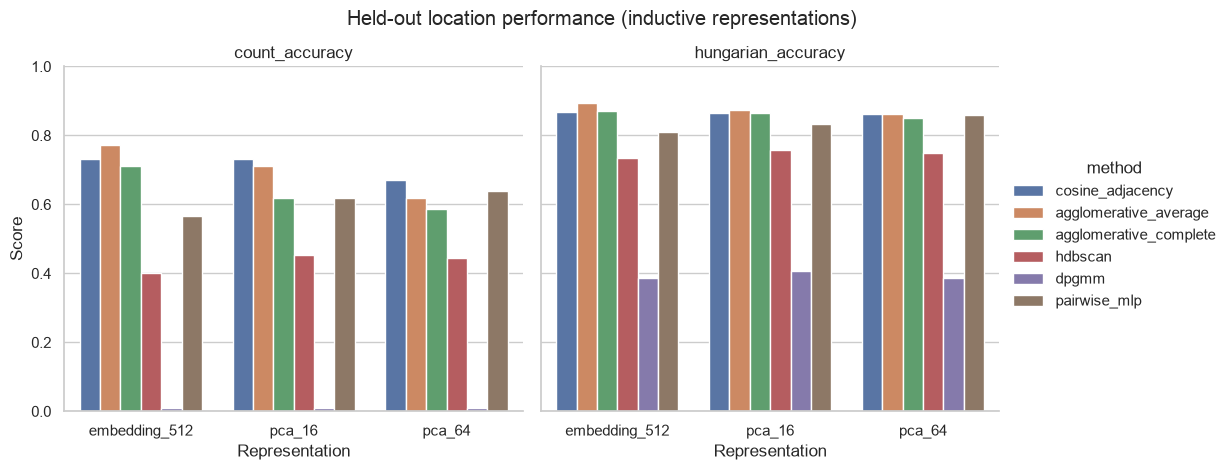

In [8]:
plot_frame = inductive_test_results.melt(
    id_vars=["method", "representation"],
    value_vars=["count_accuracy", "hungarian_accuracy"],
    var_name="metric",
    value_name="score",
)
g = sns.catplot(
    data=plot_frame,
    x="representation",
    y="score",
    hue="method",
    col="metric",
    kind="bar",
    height=4.5,
    aspect=1.15,
    sharey=True,
)
g.set_axis_labels("Representation", "Score")
g.set_titles("{col_name}")
g.set(ylim=(0, 1))
g.figure.suptitle("Held-out location performance (inductive representations)", y=1.04)
g.figure.savefig(FIGURE_DIR / "inductive_test_scores.png", dpi=180, bbox_inches="tight")
plt.show()

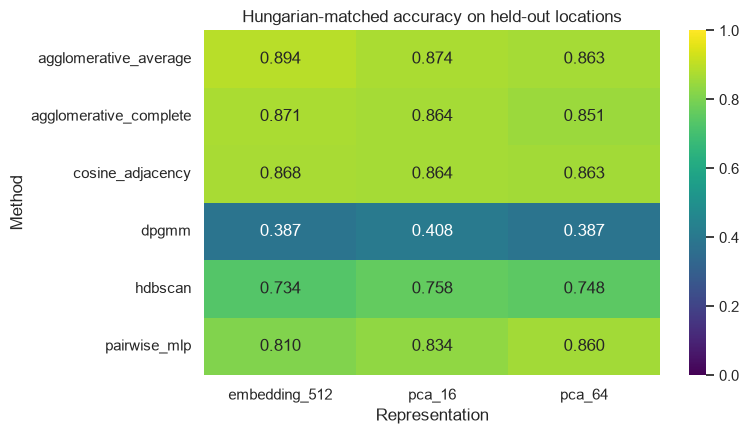

In [9]:
heatmap_data = inductive_test_results.pivot(
    index="method", columns="representation", values="hungarian_accuracy"
)
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.heatmap(heatmap_data, annot=True, fmt=".3f", vmin=0, vmax=1, cmap="viridis", ax=ax)
ax.set_title("Hungarian-matched accuracy on held-out locations")
ax.set_xlabel("Representation")
ax.set_ylabel("Method")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "hungarian_accuracy_heatmap.png", dpi=180)
plt.show()

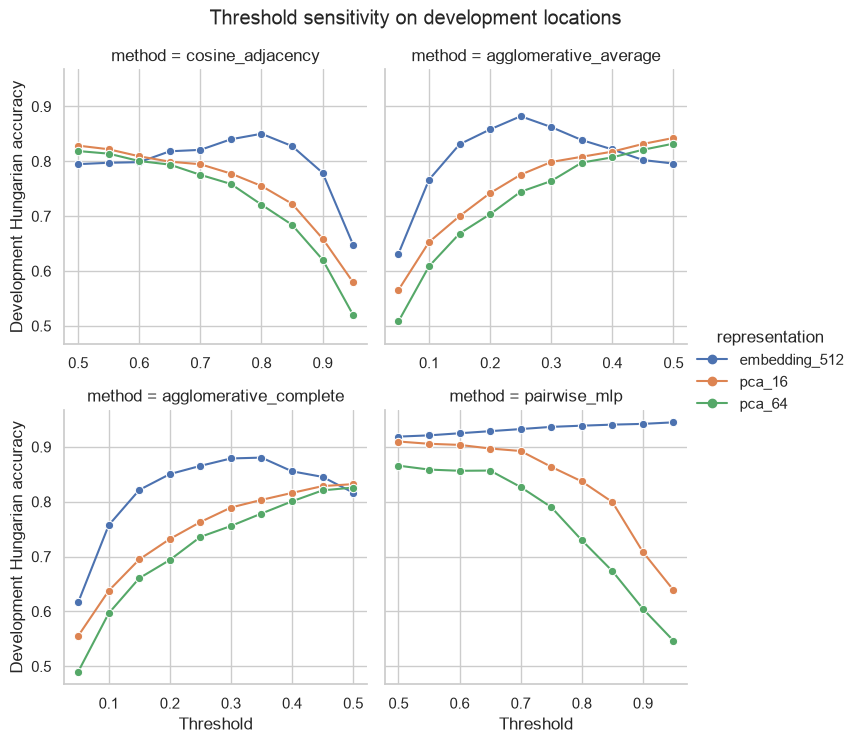

In [10]:
sensitivity = development_results[
    development_results["method"].isin(
        ["cosine_adjacency", "agglomerative_average", "agglomerative_complete", "pairwise_mlp"]
    )
].copy()
sensitivity["threshold"] = sensitivity["parameters"].map(
    lambda value: next(iter(json.loads(value).values()))
    if len(json.loads(value)) == 1
    else json.loads(value).get("distance_threshold")
)

g = sns.relplot(
    data=sensitivity.query("evaluation_regime == 'inductive'"),
    x="threshold",
    y="hungarian_accuracy",
    hue="representation",
    col="method",
    col_wrap=2,
    kind="line",
    marker="o",
    facet_kws={"sharex": False},
    height=3.6,
)
g.set_axis_labels("Threshold", "Development Hungarian accuracy")
g.figure.suptitle("Threshold sensitivity on development locations", y=1.03)
g.figure.savefig(FIGURE_DIR / "development_threshold_sensitivity.png", dpi=180, bbox_inches="tight")
plt.show()

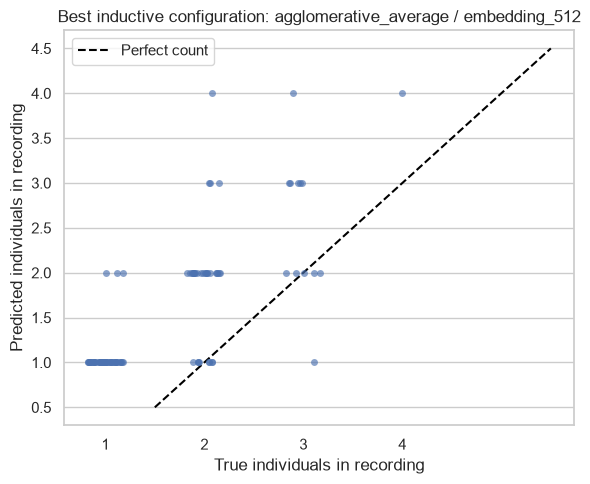

In [11]:
best_inductive = inductive_test_results.loc[
    inductive_test_results["hungarian_accuracy"].idxmax()
]
best_recordings = test_recording_results[
    test_recording_results["representation"].eq(best_inductive["representation"])
    & test_recording_results["method"].eq(best_inductive["method"])
]

max_count = max(best_recordings["true_count"].max(), best_recordings["predicted_count"].max())
fig, ax = plt.subplots(figsize=(6, 5))
sns.stripplot(
    data=best_recordings,
    x="true_count",
    y="predicted_count",
    jitter=0.18,
    alpha=0.65,
    ax=ax,
)
ax.plot([0.5, max_count + 0.5], [0.5, max_count + 0.5], "--", color="black", label="Perfect count")
ax.set(
    title=f"Best inductive configuration: {best_inductive['method']} / {best_inductive['representation']}",
    xlabel="True individuals in recording",
    ylabel="Predicted individuals in recording",
)
ax.legend()
fig.tight_layout()
fig.savefig(FIGURE_DIR / "best_model_true_vs_predicted_count.png", dpi=180)
plt.show()

## 7. Compact conclusion generated from the held-out results

In [12]:
best_count = inductive_test_results.loc[inductive_test_results["count_accuracy"].idxmax()]
best_assignment = inductive_test_results.loc[inductive_test_results["hungarian_accuracy"].idxmax()]
lowest_mae = inductive_test_results.loc[inductive_test_results["count_mae"].idxmin()]

print(
    f"Best exact-count accuracy: {best_count['method']} + {best_count['representation']} "
    f"({best_count['count_accuracy']:.3f})."
)
print(
    f"Lowest count MAE: {lowest_mae['method']} + {lowest_mae['representation']} "
    f"({lowest_mae['count_mae']:.3f})."
)
print(
    f"Best Hungarian assignment accuracy: {best_assignment['method']} + "
    f"{best_assignment['representation']} ({best_assignment['hungarian_accuracy']:.3f})."
)
print(f"All machine-readable outputs are in: {RESULT_DIR}")

Best exact-count accuracy: agglomerative_average + embedding_512 (0.773).
Lowest count MAE: agglomerative_average + embedding_512 (0.247).
Best Hungarian assignment accuracy: agglomerative_average + embedding_512 (0.894).
All machine-readable outputs are in: /Users/yomaugbovo/birdcount/outputs/individual_counting_experiment
